# 06 — Threshold, Calibration & Review Strategy

This notebook converts fraud-risk probabilities into an operational review strategy.

The analysis uses the month 6 validation period to:
- evaluate probability calibration,
- compare classification thresholds,
- measure precision–recall trade-offs,
- estimate review volume,
- calculate fraud recall at fixed review capacities,
- select an operating threshold.

Month 7 remains untouched for final evaluation.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(
    r"D:\bank-account-fraud-decision-system"
)

data_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "fraud_modeling_dataset.parquet"
)

df = pd.read_parquet(data_path)

train_df = df[
    df["month"].between(0, 5)
].copy()

val_df = df[
    df["month"] == 6
].copy()

test_df = df[
    df["month"] == 7
].copy()

target = "fraud_bool"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_val = val_df.drop(columns=[target])
y_val = val_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (794989, 40)
Validation: (108168, 40)
Test: (96843, 40)


In [3]:
from catboost import CatBoostClassifier

cat_features = [
    "payment_type",
    "employment_status",
    "housing_status",
    "source",
    "device_os"
]

X_train_cb = X_train.copy()
X_val_cb = X_val.copy()

for col in cat_features:
    X_train_cb[col] = (
        X_train_cb[col]
        .fillna("Missing")
        .astype(str)
    )

    X_val_cb[col] = (
        X_val_cb[col]
        .fillna("Missing")
        .astype(str)
    )

In [4]:
final_cat_model = CatBoostClassifier(
    depth=5,
    learning_rate=0.05,
    iterations=631,
    loss_function="Logloss",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

final_cat_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features
)

CatBoostClassifier(auto_class_weights='Balanced', depth=5, iterations=631, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=False)

In [5]:
y_val_proba = final_cat_model.predict_proba(
    X_val_cb
)[:, 1]

print("Probability range:", y_val_proba.min(), "to", y_val_proba.max())
print("Mean predicted probability:", y_val_proba.mean())
print("Actual validation fraud rate:", y_val.mean())

Probability range: 0.00022123904501662172 to 0.9991478567341802
Mean predicted probability: 0.28372138525066243
Actual validation fraud rate: 0.013405073589231566


## 1. Probability Calibration Check

The class-weighted CatBoost model produces useful fraud-risk rankings, but its predicted scores may not represent true fraud probabilities.

Calibration is assessed by comparing average predicted risk with the observed fraud rate across probability bins.

In [6]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_val,
    y_val_proba,
    n_bins=10,
    strategy="quantile"
)

calibration_df = pd.DataFrame({
    "Mean_Predicted_Probability": prob_pred,
    "Observed_Fraud_Rate": prob_true
})

display(calibration_df)

,Mean_Predicted_Probability,Observed_Fraud_Rate
0,0.015373,0.000185
1,0.040873,0.000740
2,0.070807,0.000924
3,0.109307,0.001202
4,0.160586,0.001941
5,0.227988,0.003421
6,0.318524,0.005455
7,0.441119,0.010077
8,0.611076,0.021910
9,0.841549,0.088195


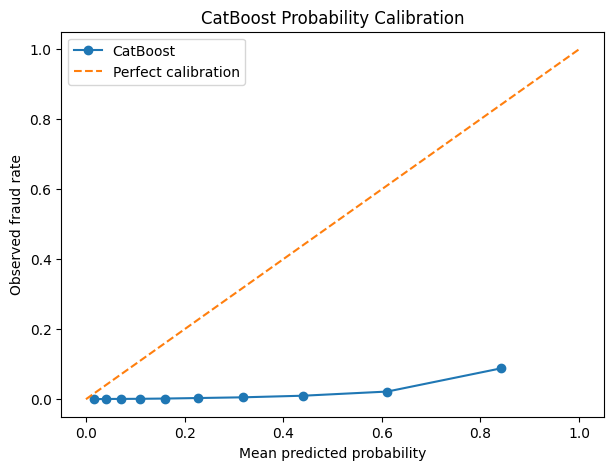

In [7]:
plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="CatBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraud rate")
plt.title("CatBoost Probability Calibration")
plt.legend()
plt.show()

## 2. Temporal Calibration Setup

The class-weighted CatBoost model provides strong fraud-risk ranking but substantially overestimates absolute fraud probabilities.

To calibrate scores without leaking future information:

- Months 0–4 are used to train the fraud model.
- Month 5 is used only to fit the probability calibrator.
- Month 6 is reserved for threshold and review-strategy selection.
- Month 7 remains untouched for final evaluation.

In [8]:
model_train_df = df[
    df["month"].between(0, 4)
].copy()

calibration_df = df[
    df["month"] == 5
].copy()

strategy_df = df[
    df["month"] == 6
].copy()

final_test_df = df[
    df["month"] == 7
].copy()

target = "fraud_bool"

X_model_train = model_train_df.drop(columns=[target])
y_model_train = model_train_df[target]

X_cal = calibration_df.drop(columns=[target])
y_cal = calibration_df[target]

X_strategy = strategy_df.drop(columns=[target])
y_strategy = strategy_df[target]

X_final_test = final_test_df.drop(columns=[target])
y_final_test = final_test_df[target]

print("Model training:", X_model_train.shape)
print("Calibration:", X_cal.shape)
print("Strategy validation:", X_strategy.shape)
print("Final test:", X_final_test.shape)

print("\nFraud rates:")
print("Training:", y_model_train.mean())
print("Calibration:", y_cal.mean())
print("Strategy:", y_strategy.mean())
print("Final test:", y_final_test.mean())

Model training: (675666, 40)
Calibration: (119323, 40)
Strategy validation: (108168, 40)
Final test: (96843, 40)

Fraud rates:
Training: 0.009975342846909568
Calibration: 0.01182504630289215
Strategy: 0.013405073589231566
Final test: 0.014745515938167962


In [9]:
X_model_train_cb = X_model_train.copy()
X_cal_cb = X_cal.copy()
X_strategy_cb = X_strategy.copy()
X_final_test_cb = X_final_test.copy()

for col in cat_features:
    X_model_train_cb[col] = (
        X_model_train_cb[col]
        .fillna("Missing")
        .astype(str)
    )

    X_cal_cb[col] = (
        X_cal_cb[col]
        .fillna("Missing")
        .astype(str)
    )

    X_strategy_cb[col] = (
        X_strategy_cb[col]
        .fillna("Missing")
        .astype(str)
    )

    X_final_test_cb[col] = (
        X_final_test_cb[col]
        .fillna("Missing")
        .astype(str)
    )

In [10]:
calibration_base_model = CatBoostClassifier(
    depth=5,
    learning_rate=0.05,
    iterations=631,
    loss_function="Logloss",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

calibration_base_model.fit(
    X_model_train_cb,
    y_model_train,
    cat_features=cat_features
)

CatBoostClassifier(auto_class_weights='Balanced', depth=5, iterations=631, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=False)

In [11]:
cal_raw_proba = calibration_base_model.predict_proba(
    X_cal_cb
)[:, 1]

print("Mean raw model score:", cal_raw_proba.mean())
print("Actual month-5 fraud rate:", y_cal.mean())

Mean raw model score: 0.2152556930555418
Actual month-5 fraud rate: 0.01182504630289215


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    brier_score_loss,
    average_precision_score,
    roc_auc_score
)

# Convert raw CatBoost probabilities to logits
eps = 1e-6

cal_raw_clipped = np.clip(
    cal_raw_proba,
    eps,
    1 - eps
)

cal_logits = np.log(
    cal_raw_clipped / (1 - cal_raw_clipped)
).reshape(-1, 1)

# Fit Platt calibrator on month 5
platt_calibrator = LogisticRegression()

platt_calibrator.fit(
    cal_logits,
    y_cal
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [13]:
strategy_raw_proba = calibration_base_model.predict_proba(
    X_strategy_cb
)[:, 1]

In [14]:
strategy_raw_clipped = np.clip(
    strategy_raw_proba,
    eps,
    1 - eps
)

strategy_logits = np.log(
    strategy_raw_clipped
    / (1 - strategy_raw_clipped)
).reshape(-1, 1)

In [16]:
strategy_calibrated_proba = (
    platt_calibrator
    .predict_proba(strategy_logits)[:, 1]
)

In [17]:
print(
    "Actual fraud rate:",
    y_strategy.mean()
)

print(
    "Mean raw CatBoost score:",
    strategy_raw_proba.mean()
)

print(
    "Mean calibrated probability:",
    strategy_calibrated_proba.mean()
)

Actual fraud rate: 0.013405073589231566
Mean raw CatBoost score: 0.22729008699139663
Mean calibrated probability: 0.01356801323725515


In [18]:
print(
    "Raw Brier score:",
    brier_score_loss(
        y_strategy,
        strategy_raw_proba
    )
)

print(
    "Calibrated Brier score:",
    brier_score_loss(
        y_strategy,
        strategy_calibrated_proba
    )
)

Raw Brier score: 0.10409728026059296
Calibrated Brier score: 0.011923144225041439


In [19]:
print(
    "Raw PR-AUC:",
    average_precision_score(
        y_strategy,
        strategy_raw_proba
    )
)

print(
    "Calibrated PR-AUC:",
    average_precision_score(
        y_strategy,
        strategy_calibrated_proba
    )
)

print(
    "Raw ROC-AUC:",
    roc_auc_score(
        y_strategy,
        strategy_raw_proba
    )
)

print(
    "Calibrated ROC-AUC:",
    roc_auc_score(
        y_strategy,
        strategy_calibrated_proba
    )
)

Raw PR-AUC: 0.18502864317055956
Calibrated PR-AUC: 0.18502864317055956
Raw ROC-AUC: 0.8920965276839832
Calibrated ROC-AUC: 0.8920965276839832


### Calibration Result

Platt scaling substantially improved the probability calibration of the class-weighted CatBoost model.

The mean calibrated fraud probability decreased from 22.73% to 1.36%, closely matching the observed fraud rate of 1.34% in the strategy-validation period.

The Brier score improved from 0.1041 to 0.0119, while PR-AUC and ROC-AUC remained unchanged. This confirms that calibration improved the interpretation of predicted probabilities without altering the model's ranking ability.

## 3. Review-Capacity Analysis

Fraud teams usually cannot manually review every application flagged by a model. The model is therefore evaluated under fixed review capacities.

Applications are ranked by calibrated fraud probability, and the highest-risk:
- 1%
- 2%
- 5%
- 10%

are selected for review.

In [20]:
strategy_results = []

review_rates = [
    0.01,
    0.02,
    0.05,
    0.10
]

strategy_eval = pd.DataFrame({
    "actual": y_strategy.values,
    "probability": strategy_calibrated_proba
})

strategy_eval = strategy_eval.sort_values(
    "probability",
    ascending=False
).reset_index(drop=True)

total_fraud = strategy_eval["actual"].sum()

for review_rate in review_rates:

    review_count = int(
        len(strategy_eval) * review_rate
    )

    reviewed = strategy_eval.iloc[
        :review_count
    ]

    fraud_found = reviewed["actual"].sum()

    precision = (
        fraud_found / review_count
    )

    recall = (
        fraud_found / total_fraud
    )

    strategy_results.append({
        "Review_Rate": review_rate,
        "Applications_Reviewed": review_count,
        "Fraud_Found": int(fraud_found),
        "Precision": precision,
        "Recall": recall
    })

review_strategy_df = pd.DataFrame(
    strategy_results
)

review_strategy_df["Review_Rate_Pct"] = (
    review_strategy_df["Review_Rate"]
    * 100
)

review_strategy_df["Precision_Pct"] = (
    review_strategy_df["Precision"]
    * 100
)

review_strategy_df["Recall_Pct"] = (
    review_strategy_df["Recall"]
    * 100
)

display(
    review_strategy_df[
        [
            "Review_Rate_Pct",
            "Applications_Reviewed",
            "Fraud_Found",
            "Precision_Pct",
            "Recall_Pct"
        ]
    ]
)

,Review_Rate_Pct,Applications_Reviewed,Fraud_Found,Precision_Pct,Recall_Pct
0,1.0,1081,296,27.382054,20.413793
1,2.0,2163,451,20.850670,31.103448
2,5.0,5408,729,13.480030,50.275862
3,10.0,10816,960,8.875740,66.206897


### Review-Capacity Interpretation

The calibrated CatBoost model provides substantial operational concentration of fraud risk.

Reviewing only the top 1% of applications captures 20.4% of all fraud cases, while a 5% review capacity captures approximately 50.3% of fraud. Expanding review capacity to 10% increases fraud recall to 66.2%.

The 5% review scenario is selected as the primary operating point because it captures approximately half of all fraud cases while limiting manual investigation to one twentieth of incoming applications.

In [21]:
selected_review_rate = 0.05

review_count = int(
    len(strategy_eval) * selected_review_rate
)

selected_threshold = (
    strategy_eval
    .iloc[review_count - 1]["probability"]
)

print(
    "Selected review rate:",
    selected_review_rate * 100,
    "%"
)

print(
    "Calibrated probability threshold:",
    selected_threshold
)

Selected review rate: 5.0 %
Calibrated probability threshold: 0.05820830905478956


In [22]:
strategy_predictions = (
    strategy_calibrated_proba
    >= selected_threshold
).astype(int)

In [23]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print(
    "Precision:",
    precision_score(
        y_strategy,
        strategy_predictions,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_strategy,
        strategy_predictions
    )
)

print(
    "F1:",
    f1_score(
        y_strategy,
        strategy_predictions
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_strategy,
        strategy_predictions
    )
)

Precision: 0.13480029585798817
Recall: 0.5027586206896552
F1: 0.2125984251968504

Confusion Matrix:
[[102039   4679]
 [   721    729]]


### Selected Operating Policy

A 5% review-capacity policy is selected using month 6 validation data.

At this operating point, the calibrated model achieves 13.48% precision and 50.28% recall, identifying 729 of 1,450 fraud cases while sending approximately 5% of applications for manual review.

This review policy and its corresponding calibrated probability threshold are frozen before evaluation on the final month 7 test period.

In [24]:
print(
    "Frozen calibrated probability threshold:",
    selected_threshold
)

Frozen calibrated probability threshold: 0.05820830905478956


## 4. Final Test Evaluation

The final model is evaluated once on month 7 using the operating policy selected from month 6.

No model tuning, calibration fitting, or threshold adjustment is performed using month 7. This preserves the test period as an unbiased estimate of future performance.

In [25]:
final_test_raw_proba = calibration_base_model.predict_proba(
    X_final_test_cb
)[:, 1]

In [26]:
final_test_raw_clipped = np.clip(
    final_test_raw_proba,
    eps,
    1 - eps
)

final_test_logits = np.log(
    final_test_raw_clipped
    / (1 - final_test_raw_clipped)
).reshape(-1, 1)

In [27]:
final_test_calibrated_proba = (
    platt_calibrator
    .predict_proba(final_test_logits)[:, 1]
)

In [28]:
final_test_pred = (
    final_test_calibrated_proba
    >= selected_threshold
).astype(int)

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix
)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_final_test,
            final_test_pred
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_final_test,
            final_test_pred,
            zero_division=0
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_final_test,
            final_test_pred
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_final_test,
            final_test_pred
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_final_test,
            final_test_calibrated_proba
        ),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_final_test,
            final_test_calibrated_proba
        ),
        4
    )
)

print(
    "Brier score:",
    round(
        brier_score_loss(
            y_final_test,
            final_test_calibrated_proba
        ),
        4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_final_test,
        final_test_pred
    )
)

Accuracy: 0.9643
Precision: 0.1989
Recall: 0.4685
F1: 0.2793
ROC-AUC: 0.8959
PR-AUC: 0.218
Brier score: 0.0129

Confusion Matrix:
[[92721  2694]
 [  759   669]]


In [30]:
test_review_rate = (
    final_test_pred.mean() * 100
)

print(
    "Actual test review rate:",
    round(test_review_rate, 2),
    "%"
)

Actual test review rate: 3.47 %


## Final Test Interpretation

The frozen month-6 review policy generalized well to the untouched month-7 test period.

The calibrated CatBoost model achieved a ROC-AUC of 0.8959 and PR-AUC of 0.2180, confirming strong fraud-ranking performance on future data.

Using the fixed operating threshold selected from month 6, the model reviewed 3.47% of month-7 applications and identified 46.85% of fraud cases. Precision increased to 19.89%, meaning approximately one in five reviewed applications was fraudulent.

The final test results demonstrate that the risk-based review strategy retained strong out-of-time performance without any threshold adjustment or model retuning on the test period.